# Exercise 12 - The diffusion equation
**Name:** Tristan Mitchell  
**Student Number:** MTCTRI001

Numerical solution of the 1D diffusion problem
$$ \frac{\partial N}{\partial t} =  k \frac{\partial^2 N}{\partial x^2}$$ 
using an explicit scheme

$N(x,t)$ represents the evolution of the dissolved nitrogen (DIN) concentration along the estuary over time

### AI Declaration
I used ChatGPT to help me get my calculations into LaTeX form for markdown. I also ran the exercise questions through Claude.ai to help me better understand what was being asked. I also used Claude.ai to help me understand what each variable does and what changing it would do. 


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
# constants
SECPERDAY = 86400.
M2KM = 1000

## User defined parameters

In [2]:
# problem parameters
kappa=1.0e3   # Eddy diffusion coefficient [m2 s-1]
dx=500         # X resolution [m]
dt=100         # time step [s]
t0=0.          # initial time
tmax=0.12      # duration of simulation [days]
xmax=10.0e3    # length of the basin [m]

# Parameters of the initial DIN spillage
N0 = 20.       # baseline concentration [mmol/m3]
sigma = 1000.  # width [m]
A = 100.       # amplitude [mmol/m3]

## Initial function and grid specifications
The initial shape of the temperature distribution is a Gaussian peak function

In [3]:
# Spatial shape of the initial DIN concentration
def Gaussian(x):
    y = N0+A*np.exp(-(x/sigma)**2)
    return y

The resulting space-time grid depends on the parameters above. The non-dimensional Courant number must be smaller than 0.5 for conditional stability.

In [4]:
# time axis
NT = int(np.floor(tmax*86400/dt))+1  # number of steps (starts from 0)
# X axis (centred at 0)
x = np.arange(-xmax,xmax,dx)
IM = len(x)             # number of grid points
N = np.zeros([IM,NT])   # the array holding the numerical solution 
print('Grid steps : ',IM)
print('Number of time steps : ',NT)
print('Timestep = ',dt,' s')
print('Max numerical diffusion DX^2/DT = ',dx**2/dt,' m2/s')
print('Physical diffusion = ',kappa,' m2/s')
print('Courant number (diffusion) = ',kappa*dt/(dx**2))

Grid steps :  40
Number of time steps :  104
Timestep =  100  s
Max numerical diffusion DX^2/DT =  2500.0  m2/s
Physical diffusion =  1000.0  m2/s
Courant number (diffusion) =  0.4


## Numerical solution
Note that this code stores the solution at all times in array N for educational purposes. This allows to plot the solution at the different time steps and see how it evolves.

*This method is very inefficient for any application because it uses a lot of memory. In modern computer codes only a few time records are hold in memory. The instantaneous solution is often temporarely stored for computing time averages and then discarded.*

This part of the code is the topic of one question found in the lecture notes

In [5]:
# Compute the numerical solution using a time loop over the number of time steps
N[:,0] = Gaussian(x)    # initial condition

for n in range(NT-1):
    # Question 2
    N[0,n+1]  = N[1,n]
    N[-1,n+1] = N[-2,n]
    # discretization of the second derivative
    rhs = kappa*(N[:-2,n]-2*N[1:-1,n]+N[2:,n])/(dx**2)
    N[1:-1,n+1] = N[1:-1,n] + rhs*dt    

## Plot the result using a matplotlib animation
The animation below displays the evolution of the solution and compares it with the initial condition

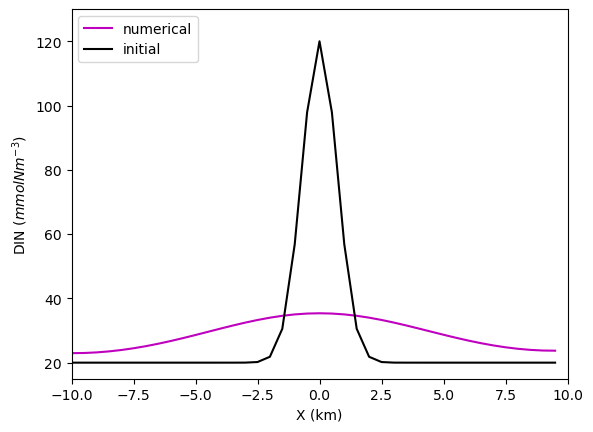

In [6]:
fig, ax = plt.subplots()
# set the axis limits
plt.axis([-xmax/M2KM, xmax/M2KM, N0-5, N0+A+10])
# first plot the initial condition and set the line attributes
sol, = ax.plot(x/M2KM, N[:,0],'m',label='numerical')
line, = ax.plot(x/M2KM, Gaussian(x),'k',label='initial')
ax.set_xlabel('X (km)')
ax.set_ylabel('DIN ($mmol N m^{-3}$)')
plt.legend(loc='upper left')

def animate(i):
    sol.set_ydata(N[:,i])  # update the numerical solution
    return sol,

# create the animation and loop (interval is in ms)
ani = animation.FuncAnimation(
    fig, animate, interval=dt, blit=True, frames=NT, repeat=True)

# display the animation as a javascript object embedded in the notebook
from IPython.display import HTML
HTML(ani.to_jshtml())

## Question 1
In the above animation plot, the rate at which the peak flattens depends on the strength of the gradient. Initially, the peak is tall and steep, causing rapid diffusion. As the peak flattens and the gradients weaken, the difference between neighbouring points decreases, slowing diffusion. 

## Question 2a

Neumann conditions in the above code:

```python
N[0, n+1] = N[1, n]

N[-1, n+1] = N[-2, n]
```

Instead of fixing the boundary to a constant value as in exercise 11, each boundary point is set to the same value as its neighbouring point. This prevents any concentration difference at the edges, stopping diffusion out of the domain. As a result, all nitrogen remains within the domain during the simulation, conserving the total amount of nitrogen throughout.

To switch to Dirichlet boundary conditions, these two lines above are replaced with:

```python
N[0, n+1] = N0

N[-1, n+1] = N0
```

This fixes the boundary points to the baseline concentration N0 = 20 mmol/m$^3$ at each time step, instead of making them equal to their neighbouring points.

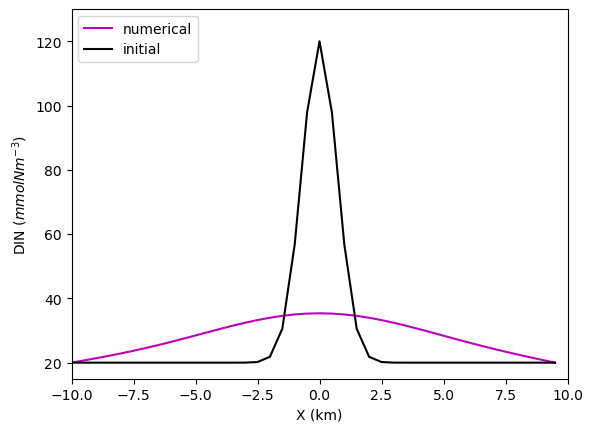

In [7]:
# Compute the numerical solution using a time loop over the number of time steps
N[:,0] = Gaussian(x)    # initial condition

for n in range(NT-1):
    # Question 2
    N[0,n+1]  = N0
    N[-1,n+1] = N0
    # discretization of the second derivative
    rhs = kappa*(N[:-2,n]-2*N[1:-1,n]+N[2:,n])/(dx**2)
    N[1:-1,n+1] = N[1:-1,n] + rhs*dt  

fig, ax = plt.subplots()
# set the axis limits
plt.axis([-xmax/M2KM, xmax/M2KM, N0-5, N0+A+10])
# first plot the initial condition and set the line attributes
sol, = ax.plot(x/M2KM, N[:,0],'m',label='numerical')
line, = ax.plot(x/M2KM, Gaussian(x),'k',label='initial')
ax.set_xlabel('X (km)')
ax.set_ylabel('DIN ($mmol N m^{-3}$)')
plt.legend(loc='upper left')

def animate(i):
    sol.set_ydata(N[:,i])  # update the numerical solution
    return sol,

# create the animation and loop (interval is in ms)
ani = animation.FuncAnimation(
    fig, animate, interval=dt, blit=True, frames=NT, repeat=True)

# display the animation as a javascript object embedded in the notebook
from IPython.display import HTML
HTML(ani.to_jshtml())

## Question 2b

With the Neumann boundary conditions, the DIN concentration stays above 20 mmol N m$^{-3}$ throughout the simulation, and the peak remains higher. This is because each boundary point is set equal to its neighbouring point, so there is no concentration difference at the edges, meaning no nitrogen diffuses out. All the nitrogen stays within the estuary.

Under Dirichlet boundary conditions, the DIN concentration drops to 20 mmol N m$^{-3}$ at the boundaries, allowing nitrogen to spread more broadly across the estuary, leading to a flatter peak relative to the Neumann boundary condition.

The Neumann boundary condition is more realistic because it treats boundary edges as non-physical boundaries where nitrogen is neither added nor removed. On the other hand, Dirichlet boundary conditions are less realistic, as they assume a constant external water source that maintains a concentration of 20 mmol N m$^{-3}$ in the estuary. In reality, nitrogen would naturally disperse and dilute without disappearing at the edges or needing external input.

## Question 3 Code:

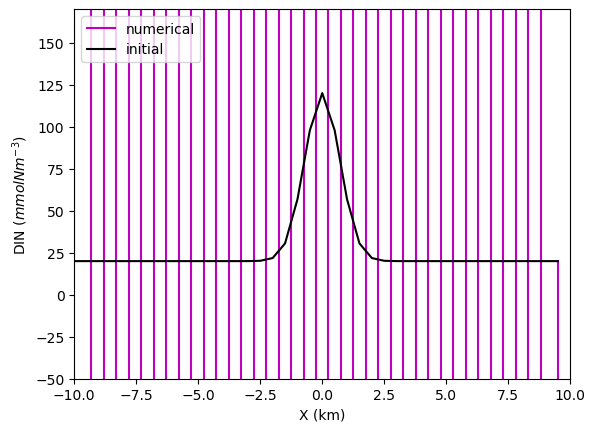

In [8]:
# problem parameters
kappa=2.0e3   # Eddy diffusion coefficient [m2 s-1]
dx=500         # X resolution [m]
dt=100         # time step [s]
t0=0.          # initial time
tmax=0.12      # duration of simulation [days]
xmax=10.0e3    # length of the basin [m]

# Parameters of the initial DIN spillage
N0 = 20.       # baseline concentration [mmol/m3]
sigma = 1000.  # width [m]
A = 100.       # amplitude [mmol/m3]

# Compute the numerical solution using a time loop over the number of time steps
N[:,0] = Gaussian(x)    # initial condition

for n in range(NT-1):
    # Question 2
    N[0,n+1]  = N0
    N[-1,n+1] = N0
    # discretization of the second derivative
    rhs = kappa*(N[:-2,n]-2*N[1:-1,n]+N[2:,n])/(dx**2)
    N[1:-1,n+1] = N[1:-1,n] + rhs*dt    


fig, ax = plt.subplots()
# set the axis limits
plt.axis([-xmax/M2KM, xmax/M2KM, -50, N0+A+50])

# first plot the initial condition and set the line attributes
sol, = ax.plot(x/M2KM, N[:,0],'m',label='numerical')
line, = ax.plot(x/M2KM, Gaussian(x),'k',label='initial')
ax.set_xlabel('X (km)')
ax.set_ylabel('DIN ($mmol N m^{-3}$)')
plt.legend(loc='upper left')

def animate(i):
    sol.set_ydata(N[:,i])  # update the numerical solution
    return sol,

# create the animation and loop (interval is in ms)
ani = animation.FuncAnimation(
    fig, animate, interval=dt, blit=True, frames=NT, repeat=True)

# display the animation as a javascript object embedded in the notebook
from IPython.display import HTML
HTML(ani.to_jshtml())

## Question 3a

Looking at the output from:

```python
print('Courant number (diffusion) = ',kappa*dt/(dx**2))
```

We can see that the Courant number (diffusion) = 0.4, which is below the stability limit of 0.5, so the original code is stable. Doubling the diffusivity coefficient increases the Courant number to:

$$
D = \kappa \frac{\Delta t}{\Delta x^2}
= 2000 \times \frac{100}{500^2}
= 0.8
$$

This exceeds the stability limit, leading to an unstable numerical solution. As a result, oscillations occur throughout the above simulation. This is due to an excessively high diffusion stability parameter. We also get negative concentration values, which is impossible for nitrogen. This can be fixed by reducing the time step.

## Question 3 Code fixed:

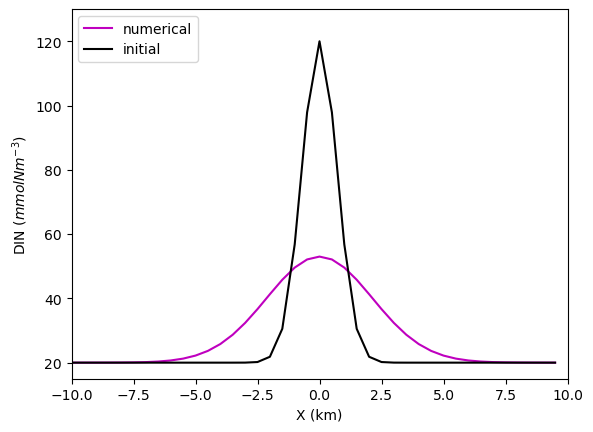

In [9]:
# problem parameters
kappa=2.0e3   # Eddy diffusion coefficient [m2 s-1]
dx=500         # X resolution [m]
dt=10         # time step [s]
t0=0.          # initial time
tmax=0.12      # duration of simulation [days]
xmax=10.0e3    # length of the basin [m]

# Parameters of the initial DIN spillage
N0 = 20.       # baseline concentration [mmol/m3]
sigma = 1000.  # width [m]
A = 100.       # amplitude [mmol/m3]

# Compute the numerical solution using a time loop over the number of time steps
N[:,0] = Gaussian(x)    # initial condition

for n in range(NT-1):
    # Question 2
    N[0,n+1]  = N0
    N[-1,n+1] = N0
    # discretization of the second derivative
    rhs = kappa*(N[:-2,n]-2*N[1:-1,n]+N[2:,n])/(dx**2)
    N[1:-1,n+1] = N[1:-1,n] + rhs*dt    


fig, ax = plt.subplots()
# set the axis limits
plt.axis([-xmax/M2KM, xmax/M2KM, N0-5, N0+A+10])

# first plot the initial condition and set the line attributes
sol, = ax.plot(x/M2KM, N[:,0],'m',label='numerical')
line, = ax.plot(x/M2KM, Gaussian(x),'k',label='initial')
ax.set_xlabel('X (km)')
ax.set_ylabel('DIN ($mmol N m^{-3}$)')
plt.legend(loc='upper left')

def animate(i):
    sol.set_ydata(N[:,i])  # update the numerical solution
    return sol,

# create the animation and loop (interval is in ms)
ani = animation.FuncAnimation(
    fig, animate, interval=dt, blit=True, frames=NT, repeat=True)

# display the animation as a javascript object embedded in the notebook
from IPython.display import HTML
HTML(ani.to_jshtml())

## Question 3b

To fix this instability, dt was reduced from 100 s to 10 s, giving a new Courant number of:

$$
D = 2000 \times \frac{10}{500^2} = 0.04
$$

This value is below the stability limit of 0.5, so the solution has stabilised (as shown in the animation plot above).